# Notebook 3 v2 — Scenario matrix with cooling events and step-offset drift

**Goal:** answer one question the v1 data cannot: do the feature sets exploit the fact that every v1 event is *warming*? v2 keeps the **same 18 episodes** (same motes, peers, times, magnitudes, gains, splits) and adds the missing cases.

**Inputs (read-only):** `clean_sensor_data.parquet` (NB2) and the v1 files `scenario_dataset.parquet`, `scenario_metadata.csv`, `scenario_config.json` (NB3).
**Outputs (new files, v1 is never overwritten):** `scenario_dataset_v2.parquet`, `scenario_metadata_v2.csv`, `scenario_config_v2.json`; tables in `outputs/notebook03_v2/`; one figure in `figures/notebook03_v2/`.

## The scenario matrix (9 variants per episode, 162 scenarios in total)

| Variant | Class label | Event | Drift (target only) | In v1? |
|---|---|---|---|---|
| NORMAL | NORMAL | none | none | yes |
| DRIFT_RAMP | DRIFT | none | linear ramp 0 → magnitude | yes |
| DRIFT_STEP | DRIFT | none | step: full magnitude from the onset | **new** |
| EVENT_WARM | EVENT | warming | none | yes |
| EVENT_COOL | EVENT | **cooling** | none | **new** |
| ED_WARM_RAMP | EVENT_DRIFT | warming | linear ramp | yes |
| ED_WARM_STEP | EVENT_DRIFT | warming | step | **new** |
| ED_COOL_RAMP | EVENT_DRIFT | cooling | linear ramp | **new** |
| ED_COOL_STEP | EVENT_DRIFT | cooling | step | **new** |

## Rules (fixed before generating)
- **No new random draws.** Everything is derived from the stored v1 episode parameters, so the four v1 variants must come out **identical** to v1 (checked cell by cell).
- **Cooling = the warming event with its sign flipped**: same peak, same per-mote gains, same timing.
- **Step = the same signed magnitude as the episode's ramp, applied in full from the onset** (when the label starts). It has the same final bias as the ramp but a larger average bias, so it should be *easier*. That difference is intentional. ED_WARM_STEP and ED_COOL_RAMP each differ from ED_WARM_RAMP in exactly one factor.
- **Labels keep the same four classes.** `scenario` is still the class name; the new column `variant` identifies the exact scenario. Label rule unchanged: the class name inside `[scenario_start, scenario_end]`, `NORMAL` outside.
- New descriptive columns: `variant`, `event_direction`, `drift_type`, `interval_phase`; metadata also records the signed event peak, the drift sign, whether drift and event have the same sign, and the event phase boundaries.

**Limits to remember:** still 18 episodes and one drift magnitude per episode; injections are synthetic; the labels are still not independently verified.

In [2]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
ROOT = next((p for p in [_here, *_here.parents] if (p / "data" / "processed").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find data/processed above " + str(_here) + ". Start Jupyter inside the project folder.")
PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs" / "notebook03_v2"; FIG = ROOT / "figures" / "notebook03_v2"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

def sha256(path, chunk=1 << 24):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while block := f.read(chunk):
            h.update(block)
    return h.hexdigest()

def check(cond, msg):
    if not bool(cond):
        raise ValueError("CHECK FAILED: " + msg)
    print("PASS ", msg)
print("ROOT:", ROOT)

ROOT: C:\AIoT_Research


## 1. Scenario matrix (the only design choices in this notebook)

In [4]:
# (variant, class label, event sign: +1 warming / -1 cooling / 0 none, drift type)
VARIANTS = [
    ("NORMAL",       "NORMAL",      0, "none"),
    ("DRIFT_RAMP",   "DRIFT",       0, "linear_ramp"),
    ("DRIFT_STEP",   "DRIFT",       0, "step_offset"),
    ("EVENT_WARM",   "EVENT",      +1, "none"),
    ("EVENT_COOL",   "EVENT",      -1, "none"),
    ("ED_WARM_RAMP", "EVENT_DRIFT", +1, "linear_ramp"),
    ("ED_WARM_STEP", "EVENT_DRIFT", +1, "step_offset"),
    ("ED_COOL_RAMP", "EVENT_DRIFT", -1, "linear_ramp"),
    ("ED_COOL_STEP", "EVENT_DRIFT", -1, "step_offset"),
]
V1_VARIANTS = {"NORMAL": "NORMAL", "DRIFT_RAMP": "DRIFT", "EVENT_WARM": "EVENT", "ED_WARM_RAMP": "EVENT_DRIFT"}   # variant -> v1 scenario name
CLASSES = ["NORMAL", "DRIFT", "EVENT", "EVENT_DRIFT"]
PHASE_EDGES = (0.2, 0.8)       # interval phases: ramp-up < 20%, plateau < 80%, ramp-down afterwards (matches the event trapezoid)
print(pd.DataFrame(VARIANTS, columns=["variant", "class", "event_sign", "drift_type"]).to_string(index=False))

     variant       class  event_sign  drift_type
      NORMAL      NORMAL           0        none
  DRIFT_RAMP       DRIFT           0 linear_ramp
  DRIFT_STEP       DRIFT           0 step_offset
  EVENT_WARM       EVENT           1        none
  EVENT_COOL       EVENT          -1        none
ED_WARM_RAMP EVENT_DRIFT           1 linear_ramp
ED_WARM_STEP EVENT_DRIFT           1 step_offset
ED_COOL_RAMP EVENT_DRIFT          -1 linear_ramp
ED_COOL_STEP EVENT_DRIFT          -1 step_offset


## 2. Load v1 (read-only) and recover the 18 episode parameter sets

In [6]:
V1_FILES = [PROC / "scenario_dataset.parquet", PROC / "scenario_metadata.csv", PROC / "scenario_config.json"]
SRC_FILE = PROC / "clean_sensor_data.parquet"
for p in V1_FILES + [SRC_FILE]:
    if not p.exists():
        raise FileNotFoundError(f"Missing {p}. Run Notebooks 2 and 3 first.")
HASH_BEFORE = {p.name: sha256(p) for p in V1_FILES + [SRC_FILE]}

with open(PROC / "scenario_config.json") as f:
    V1CFG = json.load(f)
CFG = V1CFG["config"]
SEED, PEER_METHOD = V1CFG["seed"], V1CFG["peer_method"]
RAMP = CFG["event_ramp_fraction"]
V1S = pd.read_parquet(PROC / "scenario_dataset.parquet")
# float_precision="round_trip": pandas' default CSV float parser can be off by ~1e-16; this reads the stored magnitudes back bit-exactly
V1M = pd.read_csv(PROC / "scenario_metadata.csv", parse_dates=["context_start", "scenario_start", "scenario_end"], float_precision="round_trip")

src = pd.read_parquet(SRC_FILE, columns=["moteid", "timestamp", "split", CFG["target_variable"]])
src["moteid"] = src["moteid"].astype("int16"); src[CFG["target_variable"]] = src[CFG["target_variable"]].astype("float64")
wide = src.pivot(index="timestamp", columns="moteid", values=CFG["target_variable"])
split_bounds = src.groupby("split")["timestamp"].agg(["min", "max"])

# one parameter row per episode: the EVENT_DRIFT metadata row carries every parameter
EPISODES = (V1M[V1M["scenario"] == "EVENT_DRIFT"]
            [["episode_id", "split", "target_moteid", "peer_moteids", "context_start", "scenario_start", "scenario_end",
              "drift_magnitude", "event_magnitude", "event_gains"]].sort_values("episode_id").reset_index(drop=True))
check(len(V1M) == len(V1S.groupby(["episode_id", "scenario"])) == 4 * len(EPISODES), "v1 metadata and dataset describe 4 scenarios per episode")
print(len(EPISODES), "episodes:", EPISODES["split"].value_counts().to_dict(), "| source rows:", len(src))

PASS  v1 metadata and dataset describe 4 scenarios per episode
18 episodes: {'train': 10, 'validation': 4, 'test': 4} | source rows: 1785348


## 3. Episode design summary (what the 18 episodes can and cannot support)
This is printed before anything is generated, so the limits are visible up front.

In [8]:
D = EPISODES.assign(abs_drift=EPISODES["drift_magnitude"].abs(), drift_sign=np.sign(EPISODES["drift_magnitude"]).astype(int))
print("Episodes per split:", D["split"].value_counts().to_dict())
print("\n|drift| (C) by split:")
print(D.groupby("split")["abs_drift"].agg(["count", "min", "median", "max"]).round(2).to_string())
print("\nEpisodes with |drift| < 2.0 C (hard, small-drift cases):", int((D["abs_drift"] < 2.0).sum()), "of", len(D),
      "| by split:", D[D["abs_drift"] < 2.0]["split"].value_counts().to_dict())
print("Drift sign (+ / -):", int((D["drift_sign"] > 0).sum()), "/", int((D["drift_sign"] < 0).sum()),
      "| warming events combine with drift of the SAME sign in", int((D["drift_sign"] > 0).sum()),
      "episodes and OPPOSITE sign in", int((D["drift_sign"] < 0).sum()), "(cooling flips this)")
print("Event peak (C):", D["event_magnitude"].round(2).describe()[["min", "50%", "max"]].to_dict())

Episodes per split: {'train': 10, 'validation': 4, 'test': 4}

|drift| (C) by split:
            count   min  median   max
split                                
test            4  2.43    2.92  3.80
train          10  1.80    2.57  3.46
validation      4  1.71    2.26  3.81

Episodes with |drift| < 2.0 C (hard, small-drift cases): 5 of 18 | by split: {'train': 3, 'validation': 2}
Drift sign (+ / -): 11 / 7 | warming events combine with drift of the SAME sign in 11 episodes and OPPOSITE sign in 7 (cooling flips this)
Event peak (C): {'min': 2.82, '50%': 3.8200000000000003, 'max': 4.93}


## 4. Build all nine variants

In [10]:
def event_profile(frac, ramp):
    return np.clip(np.minimum(frac / ramp, (1 - frac) / ramp), 0, 1)      # identical to v1

def drift_profile(frac, kind):
    if kind == "linear_ramp":
        return np.clip(frac, 0, 1)                                         # identical to v1
    if kind == "step_offset":
        return np.ones_like(frac)                                          # full magnitude for the whole interval
    raise ValueError(kind)

def phase_of(frac):
    return np.where(frac < 0, "pre-onset", np.where(frac < PHASE_EDGES[0], "ramp-up", np.where(frac < PHASE_EDGES[1], "plateau", "ramp-down")))

def build_v2(wide, episodes):
    frames, meta = [], []
    for ep in episodes.itertuples(index=False):
        gains = {int(k): v for k, v in json.loads(ep.event_gains).items()}
        group = list(gains)
        sub = (wide.loc[ep.context_start: ep.scenario_end, group].reset_index()
                   .melt(id_vars="timestamp", var_name="moteid", value_name="original_value"))
        sub["moteid"] = sub["moteid"].astype("int16")
        sub = sub.sort_values(["moteid", "timestamp"], kind="stable").reset_index(drop=True)
        frac = ((sub["timestamp"] - ep.scenario_start) / (ep.scenario_end - ep.scenario_start)).to_numpy()
        in_int = ((sub["timestamp"] >= ep.scenario_start) & (sub["timestamp"] <= ep.scenario_end)).to_numpy()
        is_target = (sub["moteid"] == ep.target_moteid).to_numpy()
        gain = sub["moteid"].map(gains).to_numpy()
        ev_full = ep.event_magnitude * gain * event_profile(frac, RAMP)
        phase = phase_of(frac)
        rise_end = ep.scenario_start + PHASE_EDGES[0] * (ep.scenario_end - ep.scenario_start)
        fall_start = ep.scenario_start + PHASE_EDGES[1] * (ep.scenario_end - ep.scenario_start)
        for variant, cls, esign, dtype in VARIANTS:
            has_event, has_drift = esign != 0, dtype != "none"
            df = sub.copy()
            df["event_component"] = np.where(has_event & in_int, esign * ev_full, 0.0)
            df["drift_component"] = np.where(has_drift & in_int & is_target, ep.drift_magnitude * (drift_profile(frac, dtype) if has_drift else 0.0), 0.0)
            observed = df["original_value"].notna().to_numpy()
            df["injected_change"] = np.where(observed, df["event_component"] + df["drift_component"], 0.0)
            df["modified_value"] = df["original_value"] + df["injected_change"]            # NaN stays NaN
            df["episode_id"], df["scenario"], df["variant"], df["split"] = ep.episode_id, cls, variant, ep.split
            df["label"] = np.where(in_int, cls, "NORMAL") if cls != "NORMAL" else "NORMAL"
            df["is_target"], df["in_interval"], df["interval_phase"] = is_target, in_int, phase
            df["event_direction"] = {1: "warming", -1: "cooling", 0: "none"}[esign]
            df["drift_type"] = dtype
            df["scenario_start"], df["scenario_end"] = ep.scenario_start, ep.scenario_end
            df["event_group"] = ",".join(map(str, group)) if has_event else ""
            df["is_synthetic"] = df["injected_change"] != 0
            frames.append(df)
            changed = df.loc[df["is_synthetic"], "moteid"].unique()
            dsign = int(np.sign(ep.drift_magnitude)) if has_drift else 0
            meta.append({
                "scenario_id": f"{ep.episode_id}_{variant}", "episode_id": ep.episode_id, "scenario": cls, "split": ep.split,
                "target_moteid": ep.target_moteid, "peer_moteids": ep.peer_moteids,
                "event_affected_moteids": ",".join(map(str, group)) if has_event else "",
                "drift_moteid": ep.target_moteid if has_drift else np.nan,
                "context_start": ep.context_start, "scenario_start": ep.scenario_start, "scenario_end": ep.scenario_end,
                "drift_type": dtype, "drift_magnitude": ep.drift_magnitude if has_drift else 0.0,
                "event_profile": "trapezoid" if has_event else "none", "event_magnitude": ep.event_magnitude if has_event else 0.0,
                "event_gains": ep.event_gains if has_event else "",
                "n_rows": len(df), "n_observed": int(observed.sum()), "n_affected_records": int(df["is_synthetic"].sum()),
                "affected_moteids": ",".join(map(str, sorted(changed))), "random_seed": SEED, "peer_method": PEER_METHOD,
                "variant": variant, "event_direction": {1: "warming", -1: "cooling", 0: "none"}[esign], "event_sign": esign,
                "event_signed_peak": esign * ep.event_magnitude if has_event else 0.0, "drift_sign": dsign,
                "drift_event_relation": ("none" if not (has_event and has_drift) else ("same_sign" if dsign == esign else "opposite_sign")),
                "event_rise_end": rise_end if has_event else pd.NaT, "event_fall_start": fall_start if has_event else pd.NaT,
            })
    cols = ["episode_id", "scenario", "variant", "label", "split", "moteid", "timestamp", "is_target", "in_interval", "interval_phase",
            "original_value", "modified_value", "injected_change", "event_component", "drift_component",
            "event_direction", "drift_type", "is_synthetic", "scenario_start", "scenario_end", "event_group"]
    return pd.concat(frames, ignore_index=True)[cols], pd.DataFrame(meta)

scen, meta = build_v2(wide, EPISODES)
print("scenario rows:", len(scen), "| metadata rows:", len(meta), "| episodes x variants:", len(EPISODES), "x", len(VARIANTS))
print("\nRows per variant:\n", scen["variant"].value_counts().reindex([v[0] for v in VARIANTS]).to_string())
print("\nSynthetically changed records per variant:\n", scen[scen["is_synthetic"]].groupby("variant").size().reindex([v[0] for v in VARIANTS], fill_value=0).to_string())

scenario rows: 341010 | metadata rows: 162 | episodes x variants: 18 x 9

Rows per variant:
 variant
NORMAL          37890
DRIFT_RAMP      37890
DRIFT_STEP      37890
EVENT_WARM      37890
EVENT_COOL      37890
ED_WARM_RAMP    37890
ED_WARM_STEP    37890
ED_COOL_RAMP    37890
ED_COOL_STEP    37890

Synthetically changed records per variant:
 variant
NORMAL              0
DRIFT_RAMP       5284
DRIFT_STEP       5299
EVENT_WARM      26467
EVENT_COOL      26467
ED_WARM_RAMP    26480
ED_WARM_STEP    26495
ED_COOL_RAMP    26480
ED_COOL_STEP    26495


## 5. One look at the variants (episode E01)

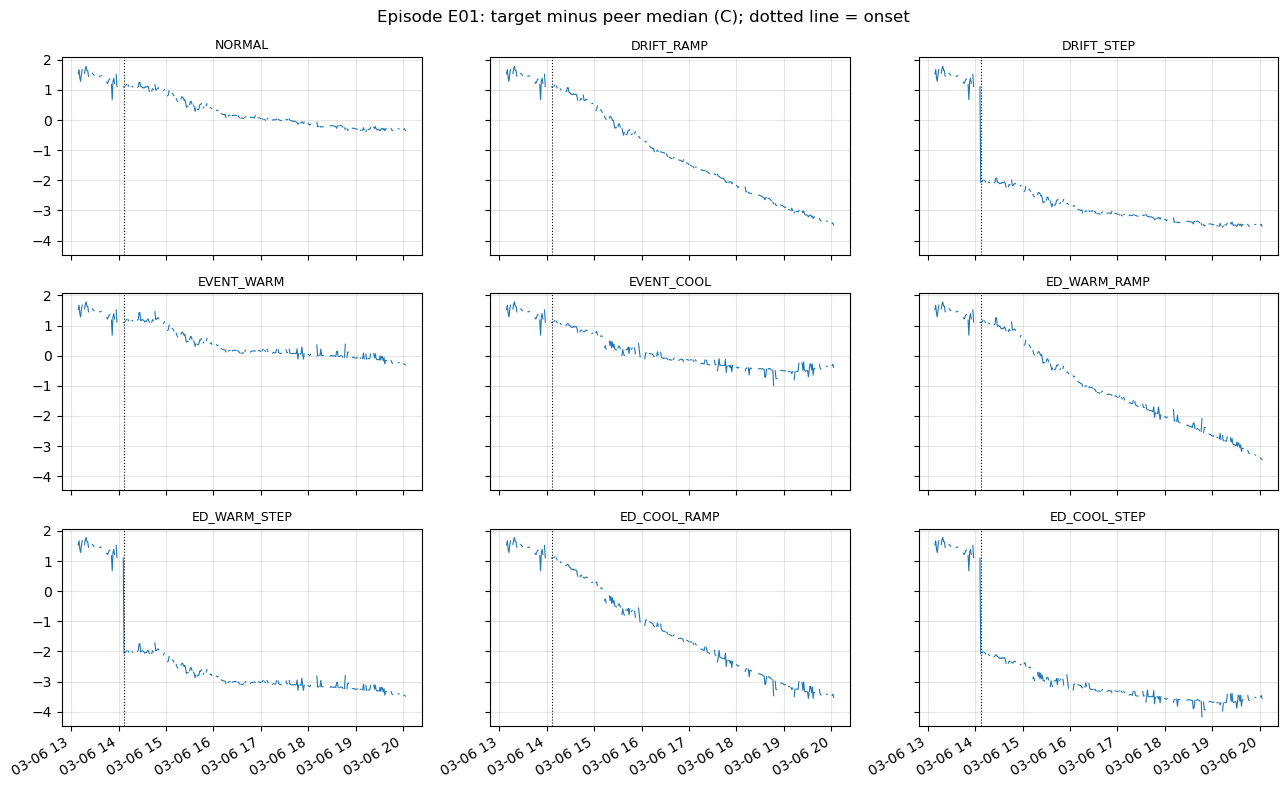

In [12]:
ep0 = EPISODES["episode_id"].iloc[0]; tgt0 = int(EPISODES["target_moteid"].iloc[0])
fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True, sharey=True)
for ax, (variant, cls, esign, dtype) in zip(axes.ravel(), VARIANTS):
    g = scen[(scen["episode_id"] == ep0) & (scen["variant"] == variant)]
    w = g.pivot(index="timestamp", columns="moteid", values="modified_value")
    dev = w[tgt0] - w.drop(columns=tgt0).median(axis=1)
    ax.plot(dev.index, dev.values, lw=0.8); ax.set_title(variant, fontsize=9)
    ax.axvline(g["scenario_start"].iloc[0], color="k", lw=0.8, ls=":")
fig.suptitle(f"Episode {ep0}: target minus peer median (C); dotted line = onset"); fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(FIG / "variants_example.png"); plt.show()

## 6. Save (new files only)

In [14]:
config_out = {"based_on": "scenario_config.json (v1)", "seed": SEED, "v1_config": CFG, "peer_method": PEER_METHOD,
              "random_draws": "none: every v2 scenario is derived from the stored v1 episode parameters",
              "variants": [{"variant": v, "class": c, "event_sign": e, "drift_type": d} for v, c, e, d in VARIANTS],
              "v1_variants": V1_VARIANTS, "candidate_peers": V1CFG["candidate_peers"], "train_end": V1CFG["train_end"],
              "peer_data_last_timestamp": V1CFG["peer_data_last_timestamp"],
              "phase_edges": list(PHASE_EDGES),
              "label_rule": "label = class name inside [scenario_start, scenario_end], NORMAL outside; unchanged from v1",
              "profiles": {"event": "trapezoid, ramp fraction = event_ramp_fraction; cooling = sign-flipped warming event",
                           "drift": {"linear_ramp": "0 -> magnitude over the interval", "step_offset": "full magnitude from scenario_start to scenario_end"}},
              "input_sha256": HASH_BEFORE}
scen.to_parquet(PROC / "scenario_dataset_v2.parquet", index=False)
meta.to_csv(PROC / "scenario_metadata_v2.csv", index=False)
with open(PROC / "scenario_config_v2.json", "w") as f:
    json.dump(config_out, f, indent=2)
meta.drop(columns=["event_gains"]).to_csv(OUT / "scenario_summary_v2.csv", index=False)
scen.groupby(["variant", "scenario", "label"]).size().rename("rows").reset_index().to_csv(OUT / "variant_label_counts.csv", index=False)
EPISODES.assign(abs_drift=EPISODES["drift_magnitude"].abs()).drop(columns=["event_gains"]).to_csv(OUT / "episode_design_summary.csv", index=False)
print("saved:", [p.name for p in sorted(PROC.glob("*_v2.*"))])

saved: ['scenario_config_v2.json', 'scenario_dataset_v2.parquet', 'scenario_metadata_v2.csv']


## 7. Validation (raises an error on any failure)

In [16]:
# reload what was saved and validate the reloaded copy
S = pd.read_parquet(PROC / "scenario_dataset_v2.parquet")
M = pd.read_csv(PROC / "scenario_metadata_v2.csv", parse_dates=["context_start", "scenario_start", "scenario_end", "event_rise_end", "event_fall_start"], float_precision="round_trip")
with open(PROC / "scenario_config_v2.json") as f:
    CJ = json.load(f)
VNAMES = [v[0] for v in VARIANTS]
KEY = ["episode_id", "moteid", "timestamp"]

# 1 inputs untouched; original_value is the real data
check({p.name: sha256(p) for p in V1_FILES + [SRC_FILE]} == HASH_BEFORE, "1. NB2 source and all v1 scenario files unchanged (hash)")
chk = S[["moteid", "timestamp", "original_value"]].astype({"moteid": "int16"}).merge(src[["moteid", "timestamp", CFG["target_variable"]]], on=["moteid", "timestamp"], how="left", indicator=True)
check((chk["_merge"] == "both").all(), "1b. every scenario row maps to a real source row")
check(((chk["original_value"] == chk[CFG["target_variable"]]) | (chk["original_value"].isna() & chk[CFG["target_variable"]].isna())).all(), "1c. original_value equals the real NB2 values")
for p in [PROC / "scenario_dataset_v2.parquet", PROC / "scenario_metadata_v2.csv", PROC / "scenario_config_v2.json", FIG / "variants_example.png",
          OUT / "scenario_summary_v2.csv", OUT / "variant_label_counts.csv", OUT / "episode_design_summary.csv"]:
    check(p.exists() and p.stat().st_size > 0, f"2. exists and non-empty: {p.name}")

# 2 design: complete, balanced, unique
check(not S.duplicated(["episode_id", "variant", "moteid", "timestamp"]).any(), "3. no duplicate (episode, variant, mote, timestamp)")
check(S.groupby("episode_id")["variant"].nunique().eq(len(VARIANTS)).all() and set(S["variant"]) == set(VNAMES), "4. every episode has all 9 variants")
check(len(M) == len(EPISODES) * len(VARIANTS) and M["scenario_id"].is_unique, "4b. metadata has exactly one row per episode x variant")
check(S.groupby("variant")["episode_id"].nunique().eq(len(EPISODES)).all(), "4c. every variant covers all 18 episodes (balanced by construction)")
vc = {v: c for v, c, _, _ in VARIANTS}
check((S["variant"].map(vc) == S["scenario"]).all() and set(S["label"]) <= set(CLASSES), "4d. each variant maps to its class; labels valid")

# 3 the four v1 variants are IDENTICAL to v1
v1cols = list(V1S.columns)
for variant, v1name in V1_VARIANTS.items():
    new = S[S["variant"] == variant][v1cols].sort_values(["episode_id", "moteid", "timestamp"]).reset_index(drop=True)
    old = V1S[V1S["scenario"] == v1name][v1cols].sort_values(["episode_id", "moteid", "timestamp"]).reset_index(drop=True)
    pd.testing.assert_frame_equal(new, old, check_exact=True)
    check(True, f"5. {variant} is identical to v1 scenario {v1name} (all {len(v1cols)} v1 columns, {len(new)} rows, exact)")
for variant, v1name in V1_VARIANTS.items():
    m_new = M[M["variant"] == variant].sort_values("episode_id").reset_index(drop=True)
    m_old = V1M[V1M["scenario"] == v1name].sort_values("episode_id").reset_index(drop=True)
    check(all(m_new[c].astype(str).equals(m_old[c].astype(str)) for c in ["episode_id", "target_moteid", "peer_moteids", "drift_magnitude", "event_magnitude", "event_gains", "n_affected_records"]),
          f"5b. metadata of {variant} matches v1")

# 4 cooling is exactly the negated warming event
def pair(a, b):
    x = S[S["variant"] == a].set_index(KEY).sort_index(); y = S[S["variant"] == b].set_index(KEY).sort_index()
    assert x.index.equals(y.index)
    return x, y
for warm, cool in [("EVENT_WARM", "EVENT_COOL"), ("ED_WARM_RAMP", "ED_COOL_RAMP"), ("ED_WARM_STEP", "ED_COOL_STEP")]:
    x, y = pair(warm, cool)
    check(np.array_equal(x["event_component"].to_numpy(), -y["event_component"].to_numpy()), f"6. {cool} event = exactly minus {warm} event (same peak, gains, timing)")
    check(np.array_equal(x["drift_component"].to_numpy(), y["drift_component"].to_numpy()), f"6b. {cool} drift equals {warm} drift")
# drift is the same whether or not an event is present
for dv, edv in [("DRIFT_RAMP", "ED_COOL_RAMP"), ("DRIFT_STEP", "ED_WARM_STEP"), ("DRIFT_STEP", "ED_COOL_STEP")]:
    x, y = pair(dv, edv)
    check(np.array_equal(x["drift_component"].to_numpy(), y["drift_component"].to_numpy()), f"6c. {edv} carries the same drift as {dv}")

# 5 direction metadata agrees with the data
for variant, _, esign, _ in VARIANTS:
    e = S.loc[S["variant"] == variant, "event_component"]
    ok = (e == 0).all() if esign == 0 else ((e * esign >= 0).all() and (e * esign > 0).any())
    check(ok, f"7. {variant}: event component has the sign of event_direction ({ {1: 'warming', -1: 'cooling', 0: 'none'}[esign] })")
check(M["event_direction"].eq(M["variant"].map({v: {1: "warming", -1: "cooling", 0: "none"}[e] for v, _, e, _ in VARIANTS})).all(), "7b. metadata event_direction matches the matrix")
check(np.allclose(M["event_signed_peak"].abs(), M["event_magnitude"]) and (np.sign(M["event_signed_peak"]) == M["event_sign"]).all(), "7c. warming and cooling variants have the same absolute peak")
rel = M[(M["event_sign"] != 0) & (M["drift_sign"] != 0)]
check(((rel["drift_sign"] == rel["event_sign"]) == (rel["drift_event_relation"] == "same_sign")).all(), "7d. drift_event_relation matches the actual signs")

# 6 drift shapes
for variant in ["DRIFT_STEP", "ED_WARM_STEP", "ED_COOL_STEP"]:
    g = S[S["variant"] == variant]; t = g[g["is_target"] & g["in_interval"]]
    mag = M[M["variant"] == variant].set_index("episode_id")["drift_magnitude"]
    check((t["drift_component"].to_numpy() == t["episode_id"].map(mag).to_numpy()).all(), f"8. {variant}: target bias equals the full signed magnitude at every in-interval minute (a true step)")
    check((g.loc[~g["is_target"], "drift_component"] == 0).all() and (g.loc[~g["in_interval"], "drift_component"] == 0).all(), f"8b. {variant}: no drift on peers or outside the interval")
    first = t.sort_values(["episode_id", "timestamp"]).groupby("episode_id").first()
    check((first["timestamp"] == first["scenario_start"]).all() and (first["label"] == vc[variant]).all(), f"8c. {variant}: the step starts at the onset, where the label starts")
for variant in ["DRIFT_RAMP", "ED_WARM_RAMP", "ED_COOL_RAMP"]:
    t = S[(S["variant"] == variant) & S["is_target"] & S["in_interval"]].sort_values(["episode_id", "timestamp"])
    check(t.groupby("episode_id")["drift_component"].apply(lambda s: (s.abs().diff().dropna() >= -1e-12).all()).all(), f"8d. {variant}: ramp never decreases (gradual)")
check((S.loc[S["variant"] == "NORMAL", ["injected_change", "event_component", "drift_component"]] == 0).all().all() and (S.loc[S["variant"] == "NORMAL", "label"] == "NORMAL").all(), "9. NORMAL: no injection, label NORMAL")
E = S[S["event_direction"] != "none"]
check(all(sorted(g.loc[g["is_synthetic"], "moteid"].unique()) == sorted([int(m) for m in g["event_group"].iloc[0].split(",")]) for _, g in E.groupby(["episode_id", "variant"])),
      "9b. every event variant affects the target and all peers")
check((S.loc[~S["in_interval"], ["event_component", "drift_component", "injected_change"]] == 0).all().all(), "9c. nothing injected outside the interval (including the 60-min context)")

# 7 reconstruction, NaNs, labels
obs = S["original_value"].notna()
check(np.allclose(S.loc[obs, "modified_value"], (S["original_value"] + S["event_component"] + S["drift_component"])[obs], atol=1e-9), "10. modified = original + event + drift (observed rows)")
check((S["modified_value"].isna() == S["original_value"].isna()).all() and np.isfinite(S[["injected_change", "event_component", "drift_component"]].to_numpy()).all(), "10b. no NaN introduced or filled; components finite")
check((S.loc[S["timestamp"] < S["scenario_start"], "label"] == "NORMAL").all() and (S.loc[S["timestamp"] < S["scenario_start"], ["event_component", "drift_component"]] == 0).all().all(), "11. before the onset: label NORMAL, nothing injected")
inn = S[S["in_interval"]]
check((inn["label"] == inn["scenario"]).all(), "11b. inside the interval the label equals the class name")

# 8 independent reconstruction of every component from (timestamp, stored metadata) alone
rec_ev, rec_dr = np.zeros(len(S)), np.zeros(len(S))
Mi = M.set_index("scenario_id")
for (ep_id, variant), idx in S.groupby(["episode_id", "variant"]).groups.items():
    m = Mi.loc[f"{ep_id}_{variant}"]; g = S.loc[idx]
    gains = {int(k): v for k, v in json.loads(V1M[(V1M["episode_id"] == ep_id) & (V1M["scenario"] == "EVENT_DRIFT")]["event_gains"].iloc[0]).items()}
    frac = ((g["timestamp"] - m["scenario_start"]) / (m["scenario_end"] - m["scenario_start"])).to_numpy()
    inn_ = ((g["timestamp"] >= m["scenario_start"]) & (g["timestamp"] <= m["scenario_end"])).to_numpy()
    if m["event_sign"] != 0:
        rec_ev[S.index.get_indexer(idx)] = np.where(inn_, m["event_signed_peak"] * g["moteid"].map(gains).to_numpy() * event_profile(frac, RAMP), 0.0)
    if m["drift_type"] != "none":
        prof = np.clip(frac, 0, 1) if m["drift_type"] == "linear_ramp" else np.ones_like(frac)
        rec_dr[S.index.get_indexer(idx)] = np.where(inn_ & g["is_target"].to_numpy(), m["drift_magnitude"] * prof, 0.0)
check(np.allclose(S["event_component"], rec_ev) and np.allclose(S["drift_component"], rec_dr), "12. every component is reproduced from (timestamp, stored metadata) alone")

# 9 metadata vs dataset, phases, splits, reproducibility, schema
cnt = S.groupby(["episode_id", "variant"]).agg(n_rows=("moteid", "size"), n_aff=("is_synthetic", "sum"), n_obs=("original_value", "count"))
mi = M.set_index(["episode_id", "variant"]).loc[cnt.index]
check((mi["n_rows"] == cnt["n_rows"]).all() and (mi["n_observed"] == cnt["n_obs"]).all() and (mi["n_affected_records"] == cnt["n_aff"]).all(), "13. metadata counts match the dataset")
fr = ((S["timestamp"] - S["scenario_start"]) / (S["scenario_end"] - S["scenario_start"])).to_numpy()
check((S["interval_phase"].to_numpy() == phase_of(fr)).all() and set(S["interval_phase"]) == {"pre-onset", "ramp-up", "plateau", "ramp-down"}, "13b. interval_phase matches the timestamp position")
check(all((S.loc[S["split"] == sp, "timestamp"].min() >= split_bounds.loc[sp, "min"]) and (S.loc[S["split"] == sp, "timestamp"].max() <= split_bounds.loc[sp, "max"]) for sp in ["train", "validation", "test"]), "13c. every row lies inside its own chronological split")
S2, M2 = build_v2(wide, EPISODES)
pd.testing.assert_frame_equal(S2, scen); pd.testing.assert_frame_equal(M2, meta)
check(True, "14. rebuilding gives identical output (no randomness)")
expected = ["episode_id", "scenario", "variant", "label", "split", "moteid", "timestamp", "is_target", "in_interval", "interval_phase",
            "original_value", "modified_value", "injected_change", "event_component", "drift_component", "event_direction", "drift_type",
            "is_synthetic", "scenario_start", "scenario_end", "event_group"]
check(list(S.columns) == expected, "15. output schema and column order correct")
print("\nALL NOTEBOOK 3 v2 CHECKS PASSED")

PASS  1. NB2 source and all v1 scenario files unchanged (hash)
PASS  1b. every scenario row maps to a real source row
PASS  1c. original_value equals the real NB2 values
PASS  2. exists and non-empty: scenario_dataset_v2.parquet
PASS  2. exists and non-empty: scenario_metadata_v2.csv
PASS  2. exists and non-empty: scenario_config_v2.json
PASS  2. exists and non-empty: variants_example.png
PASS  2. exists and non-empty: scenario_summary_v2.csv
PASS  2. exists and non-empty: variant_label_counts.csv
PASS  2. exists and non-empty: episode_design_summary.csv
PASS  3. no duplicate (episode, variant, mote, timestamp)
PASS  4. every episode has all 9 variants
PASS  4b. metadata has exactly one row per episode x variant
PASS  4c. every variant covers all 18 episodes (balanced by construction)
PASS  4d. each variant maps to its class; labels valid
PASS  5. NORMAL is identical to v1 scenario NORMAL (all 17 v1 columns, 37890 rows, exact)
PASS  5. DRIFT_RAMP is identical to v1 scenario DRIFT (all 

## 8. Summary

In [18]:
print("Episodes          :", len(EPISODES), EPISODES["split"].value_counts().to_dict(), "(identical to v1)")
print("Variants          :", len(VARIANTS), "per episode ->", len(M), "scenarios,", len(S), "rows")
print("v1 variants       : reproduced exactly (NORMAL, DRIFT_RAMP, EVENT_WARM, ED_WARM_RAMP)")
print("New variants      : DRIFT_STEP, EVENT_COOL, ED_WARM_STEP, ED_COOL_RAMP, ED_COOL_STEP")
print("Class rows        :", S.groupby("scenario").size().to_dict())
print("Outputs           :", [p.name for p in sorted(PROC.glob('*_v2.*'))])
print("Limits            : same 18 episodes, one drift magnitude per episode, synthetic injections, labels not independently verified.")
print("Next              : NB4 v2 (windows and features per variant), then NB5 v2 (standard split, cross-direction and cross-drift-type tests).")

Episodes          : 18 {'train': 10, 'validation': 4, 'test': 4} (identical to v1)
Variants          : 9 per episode -> 162 scenarios, 341010 rows
v1 variants       : reproduced exactly (NORMAL, DRIFT_RAMP, EVENT_WARM, ED_WARM_RAMP)
New variants      : DRIFT_STEP, EVENT_COOL, ED_WARM_STEP, ED_COOL_RAMP, ED_COOL_STEP
Class rows        : {'DRIFT': 75780, 'EVENT': 75780, 'EVENT_DRIFT': 151560, 'NORMAL': 37890}
Outputs           : ['scenario_config_v2.json', 'scenario_dataset_v2.parquet', 'scenario_metadata_v2.csv']
Limits            : same 18 episodes, one drift magnitude per episode, synthetic injections, labels not independently verified.
Next              : NB4 v2 (windows and features per variant), then NB5 v2 (standard split, cross-direction and cross-drift-type tests).
